## Detect functional groups in MOFs
In this notebook, we will use mofography to detect sepecifc functional groups in MOFs. We will then extend this to look for functional groups in a database of MOFs such as the CoRE MOF database. 
### Algorithm 

Under the hood, mofography uses a graph-based approach to detect functional groups. The algorithm is called subgraph isomorphism and is a well-known problem in computer science. The algorithm is implemented in the [networkx](https://networkx.github.io/) package. Detection occurs based on element and bond types. The source code is in `analyze.py` in the mofography package.

### Steps 

- Load the MOF into ASE
- Load the function group as SMARTS
- Convert both to networkx graphs, via. RDKit
- Detect the functional group in the MOF using subgraph isomorphism
- Make separate atoms object for just selected atoms and bonds in the MOF
- Visualize just hat to confirm


### Functional groups
In this example we are just looking for COO groups, which are extremely common in MOFs. If you want to look for other functional groups, please use SMARTS notation to define the functional group. And some explanation of SMARTS is provided later. 

## Imports
Import the necessary packages.

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
import sys
path_to_mgr= Path('c:/Users/Arun Gopalan/OneDrive - The University of Manchester/my_cloned_repos/mofography_general/mofography')
sys.path.append(str(path_to_mgr))
import mofography as mgr
import pickle
from ase.io import read
import networkx as nx 
from tqdm import tqdm
import plotly.graph_objects as go

## Grab a dataset
Either grab it from MOFDB or if you have pre saved file read it in to a pandas dataframe.

To grab from MOFDB use this one as a mofography example for setting ranges. This takes a long time, so it's better if you do in once and save the dataframe for future use as a feather or pickle file. In this notebook we'll just use a narrow range of void fraction and largest cavity diameter to select a materials, just so that the dataset remains small for now.   

In [2]:
# df = mgr.get_data_from_mofdb(params={'vf_min': 0.7, 'vf_max': 0.75,'lcd_min':12,'lcd_max':14, 'database':'CoREMOF 2019'})

TO read from saved file, for e.g. `.feather` file, use this example: 

In [3]:
path_to_dataset = Path('../../../../my_projects/shape_matching/core_df_gt_05.feather')
df  = pd.read_feather(path_to_dataset) # put your path here

Let's look at the first 10 MOFs in the dataset.

In [4]:
df.head(10)

,id,mofid,mofkey,hashkey,name,void_fraction,surface_area_m2g,surface_area_m2cm3,pld,lcd,...,pore_size_distribution,database,batch_number,elements,cif,url,adsorbates,heats,isotherms,mofdb_version
0,173867,None,None,9fb126ebee087f37a01307ef416072bca0d84f3bcb1a41...,ABAYIO_clean,0.6636,1936.750,1838.220,4.32260,11.39490,...,None,CoREMOF 2019,41,[],data_image0\n_cell_length_a 26.771\n_cel...,/mofs/173867.json,"[{'InChICode': 'InChI=1S/N2/c1-2', 'InChIKey':...",[],"[{'DOI': '10.1021/acs.jced.9b00835', 'adsorbat...",dc8a0295db
1,173868,None,None,c85c642b30aa4293e6d054f9fd904aa6c9559a0ea130d1...,ABAYOU_clean,0.6638,1922.330,1882.480,4.51080,11.27340,...,None,CoREMOF 2019,41,[],data_image0\n_cell_length_a 26.647\n_cel...,/mofs/173868.json,"[{'InChICode': 'InChI=1S/N2/c1-2', 'InChIKey':...",[],"[{'DOI': '10.1021/acs.jced.9b00835', 'adsorbat...",dc8a0295db
2,173870,None,None,86a93edc3ddc6c674e3c584097cc12915863f28e12c7ae...,ABESUX_clean,0.5646,466.934,1747.690,4.42492,5.87931,...,None,CoREMOF 2019,41,[],data_image0\n_cell_length_a 15.512\n_cel...,/mofs/173870.json,"[{'InChICode': 'InChI=1S/N2/c1-2', 'InChIKey':...",[],"[{'DOI': '10.1021/acs.jced.9b00835', 'adsorbat...",dc8a0295db
3,173871,None,None,2f6f65d5cda404093e20258bdcebad95ef9ab0c84d2472...,ABETAE_clean,0.5720,492.461,1821.750,4.42033,5.88295,...,None,CoREMOF 2019,41,[],data_image0\n_cell_length_a 15.52\n_cell...,/mofs/173871.json,"[{'InChICode': 'InChI=1S/N2/c1-2', 'InChIKey':...",[],"[{'DOI': '10.1021/acs.jced.9b00835', 'adsorbat...",dc8a0295db
4,173872,None,None,73d7bc006d91f2adbea02677d7685de0db8b092109f433...,ABETIN_clean,0.7302,3810.890,2275.990,7.83744,9.47418,...,None,CoREMOF 2019,41,[],data_image0\n_cell_length_a 26.9629\n_ce...,/mofs/173872.json,"[{'InChICode': 'InChI=1S/N2/c1-2', 'InChIKey':...",[],"[{'DOI': '10.1021/acs.jced.9b00835', 'adsorbat...",dc8a0295db
5,173874,None,None,a5d9dc769e7a7595faef887876e9706ef31ca32da6c7de...,ABEXEN_clean,0.7530,2463.350,1661.210,13.71870,18.80790,...,None,CoREMOF 2019,41,[],data_image0\n_cell_length_a 25.098\n_cel...,/mofs/173874.json,"[{'InChICode': 'InChI=1S/N2/c1-2', 'InChIKey':...",[],"[{'DOI': '10.1021/acs.jced.9b00835', 'adsorbat...",dc8a0295db
6,173876,None,None,a9e5e0adbd548f1764baf8ee4810343840bf9731dd1379...,ABEXOW_clean,0.5026,528.037,957.031,4.04921,4.77270,...,None,CoREMOF 2019,41,[],data_ABEXOW_clean\n_audit_creation_date ...,/mofs/173876.json,"[{'InChICode': 'InChI=1S/N2/c1-2', 'InChIKey':...",[],"[{'DOI': '10.1021/acs.jced.9b00835', 'adsorbat...",dc8a0295db
7,173882,None,None,4a17bfe0474941b2b69f89c8d2195a8497cbe5feaadb8d...,ABULOB_clean,0.5364,898.121,1184.810,4.16445,4.86958,...,None,CoREMOF 2019,41,[],data_image0\n_cell_length_a 8.5009\n_cel...,/mofs/173882.json,"[{'InChICode': 'InChI=1S/N2/c1-2', 'InChIKey':...",[],"[{'DOI': '10.1021/acs.jced.9b00835', 'adsorbat...",dc8a0295db
8,173883,None,None,df5970ecce6e1d11b0a165480f017a7b9b6228e13bb9a7...,ABUWOJ_clean,0.6210,1506.680,1745.230,4.03039,5.07969,...,None,CoREMOF 2019,41,[],data_ABUWOJ_clean\n_audit_creation_date ...,/mofs/173883.json,"[{'InChICode': 'InChI=1S/N2/c1-2', 'InChIKey':...",[],"[{'DOI': '10.1021/acs.jced.9b00835', 'adsorbat...",dc8a0295db
9,173884,None,None,0bacd0b5a2a81d06c2208c0aecd069beea712a24253d1b...,ac403674p_si_001_clean,0.5906,1089.260,1220.760,8.27985,8.50423,...,None,CoREMOF 2019,41,[],data_ac403674p_si_001_clean\n_audit_creation_d...,/mofs/173884.json,"[{'InChICode': 'InChI=1S/N2/c1-2', 'InChIKey':...",[],"[{'DOI': '10.1021/acs.jced.9b00835', 'adsorbat...",dc8a0295db


Convert them to ASE atoms objects. DO it once and save it as a pickle file for future use. 

In [5]:
# core_atoms = mgr.atoms_from_mofdb_df(df)
#uncomment this line to save the the list of ASE atoms objects
# pickle.dump(core_atoms, open('core_atoms.pkl','wb'))

Or if you have it already, load it up here: 

In [6]:
# core_atoms = pickle.load(open('./core_atoms_list.pkl','rb'))
core_atoms = pickle.load(open('../../../../my_projects/shape_matching/core_atoms_list.pkl','rb'))

Let's pick one material and test our methodology

In [7]:
mat_atoms = core_atoms[1]

## How to specify functional moeties? 

Functional moieties, also known as functional groups, can be specified using SMARTS (SMiles ARbitrary Target Specification) notation. SMARTS is a language that allows you to describe molecular patterns. It is used extensively in cheminformatics to search for structural patterns within datasets of molecules.

The SMILES pattern for a carboxylate group is C(=O)[O-].But, since we are looking for part of a MOF structure, where there isn't explicit charge on the oxygen, the SMILES pattern we should look for looks just like a carbon dioxide molecule. `C(=O)=O` represents a carbon dioxide molecule. Here's what each part of the pattern means in SMILES.

- `C`: This represents a carbon atom.
- `(` and `)`: Parentheses are used to show branching from a chain. In this case, they indicate that the things inside them are attached to the preceding carbon atom.
- `=`: This represents a double bond.
- `O`: This represents an oxygen atom.

Let's look for this functional group in the MOF.


In [8]:
# mat_atoms = core_atoms[10]
functional_groups = {
    'carboxylate': 'C(=O)=O',
}

matches = mgr.find_functional_groups(mat_atoms, functional_groups)


No node props provided, using default set: [position, scaled_position, element and atomic_number]
No edge properties provided. Use the default set: [bond_order, bond_type]


Let's look at the detected atoms for carboxylate group in the material, if any. 

In [9]:
matches

{'carboxylate': [{288: 0, 0: 1, 147: 2},
  {288: 0, 147: 1, 0: 2},
  {290: 0, 1: 1, 146: 2},
  {290: 0, 146: 1, 1: 2},
  {292: 0, 4: 1, 151: 2},
  {292: 0, 151: 1, 4: 2},
  {294: 0, 5: 1, 150: 2},
  {294: 0, 150: 1, 5: 2},
  {296: 0, 148: 1, 7: 2},
  {296: 0, 7: 1, 148: 2},
  {298: 0, 8: 1, 159: 2},
  {298: 0, 159: 1, 8: 2},
  {300: 0, 9: 1, 158: 2},
  {300: 0, 158: 1, 9: 2},
  {302: 0, 10: 1, 157: 2},
  {302: 0, 157: 1, 10: 2},
  {304: 0, 155: 1, 12: 2},
  {304: 0, 12: 1, 155: 2},
  {306: 0, 154: 1, 13: 2},
  {306: 0, 13: 1, 154: 2},
  {308: 0, 16: 1, 185: 2},
  {308: 0, 185: 1, 16: 2},
  {310: 0, 18: 1, 187: 2},
  {310: 0, 187: 1, 18: 2},
  {312: 0, 20: 1, 189: 2},
  {312: 0, 189: 1, 20: 2},
  {314: 0, 188: 1, 21: 2},
  {314: 0, 21: 1, 188: 2},
  {316: 0, 22: 1, 191: 2},
  {316: 0, 191: 1, 22: 2},
  {318: 0, 24: 1, 181: 2},
  {318: 0, 181: 1, 24: 2},
  {320: 0, 26: 1, 183: 2},
  {320: 0, 183: 1, 26: 2},
  {322: 0, 27: 1, 182: 2},
  {322: 0, 182: 1, 27: 2},
  {324: 0, 177: 1, 28: 2},


Great. It looks there are some of these grtoups in the material, which is not surfprising since, COO groups are extremely common in MOF linkers. The output is a dictionary, where each key (functional group name) carries a list of dictionaries give the atoms in the material that pattern matched to the atoms in the input functional group.

## Visualize
Now, let's use mofography to visualize and confirm that the correct atoms are detected. Notice that the COO atoms are represented in a more SMILES-like notation, with strict double bonds and no hydrogens, and it still should work.

In [10]:
# mat_atoms = read(path_to_cif)
mat_atoms = core_atoms[1]
# mat_updated =mgr.update_with_covalent_bonds(mat_atoms)

# Use thse if you need 
# aromatic_molecules = {
#     "Benzene": "c1ccccc1",
#     "Pyridine": "n1ccccc1",
#     "Pyrrole": "c1cc[nH]c1",
#     "Furane": "c1ccoc1",
#     "Thiophene": "c1ccsc1",
#     "Imidazole": "c1nccn1",
#     "Pyrazole": "c1nncn1",
#     "Oxazole": "c1nco1",
#     "Thiazole": "c1ncs1",
#     "Isoxazole": "c1noc1",
#     "Isothiazole": "c1nsc1"
# }
functional_groups = {
    'carboxylate': 'C(=O)=O',
}

matches =mgr.find_functional_groups(mat_atoms,functional_groups)
matching_indices = np.concatenate([list(m.keys()) for m in matches['carboxylate']])
# Create a list of atoms that match the indices
# matching_atoms = []
# for group, indices_list in matches.items():
#     for indices in indices_list:
#         matching_atoms.extend([mat_updated[i] for i in indices.keys()])

frame_subset_trace = mgr.plot_subset_of_atoms(mat_atoms, subset=matching_indices)


No node props provided, using default set: [position, scaled_position, element and atomic_number]
No edge properties provided. Use the default set: [bond_order, bond_type]
No node props provided, using default set: [position, scaled_position, element and atomic_number]
No edge properties provided. Use the default set: [bond_order, bond_type]


c:\Users\Public\anaconda3\envs\test\lib\site-packages\ase\atoms.py:967: VisibleDeprecationWarning: Use get_global_number_of_atoms() instead
  warnings.warn('Use get_global_number_of_atoms() instead',


No node props provided, using default set: [position, scaled_position, element and atomic_number]
No edge properties provided. Use the default set: [bond_order, bond_type]
isomorphic aromatic cycles is None, trying to calculate


(if you want to, switch out the renderer for interactive visualization)

Please note that if the functional group is spread across periodic boundaries, you might see some weird bonds in the visualization, since the atoms in the unit cell are plotted as they are without shifting to avoid confusion.

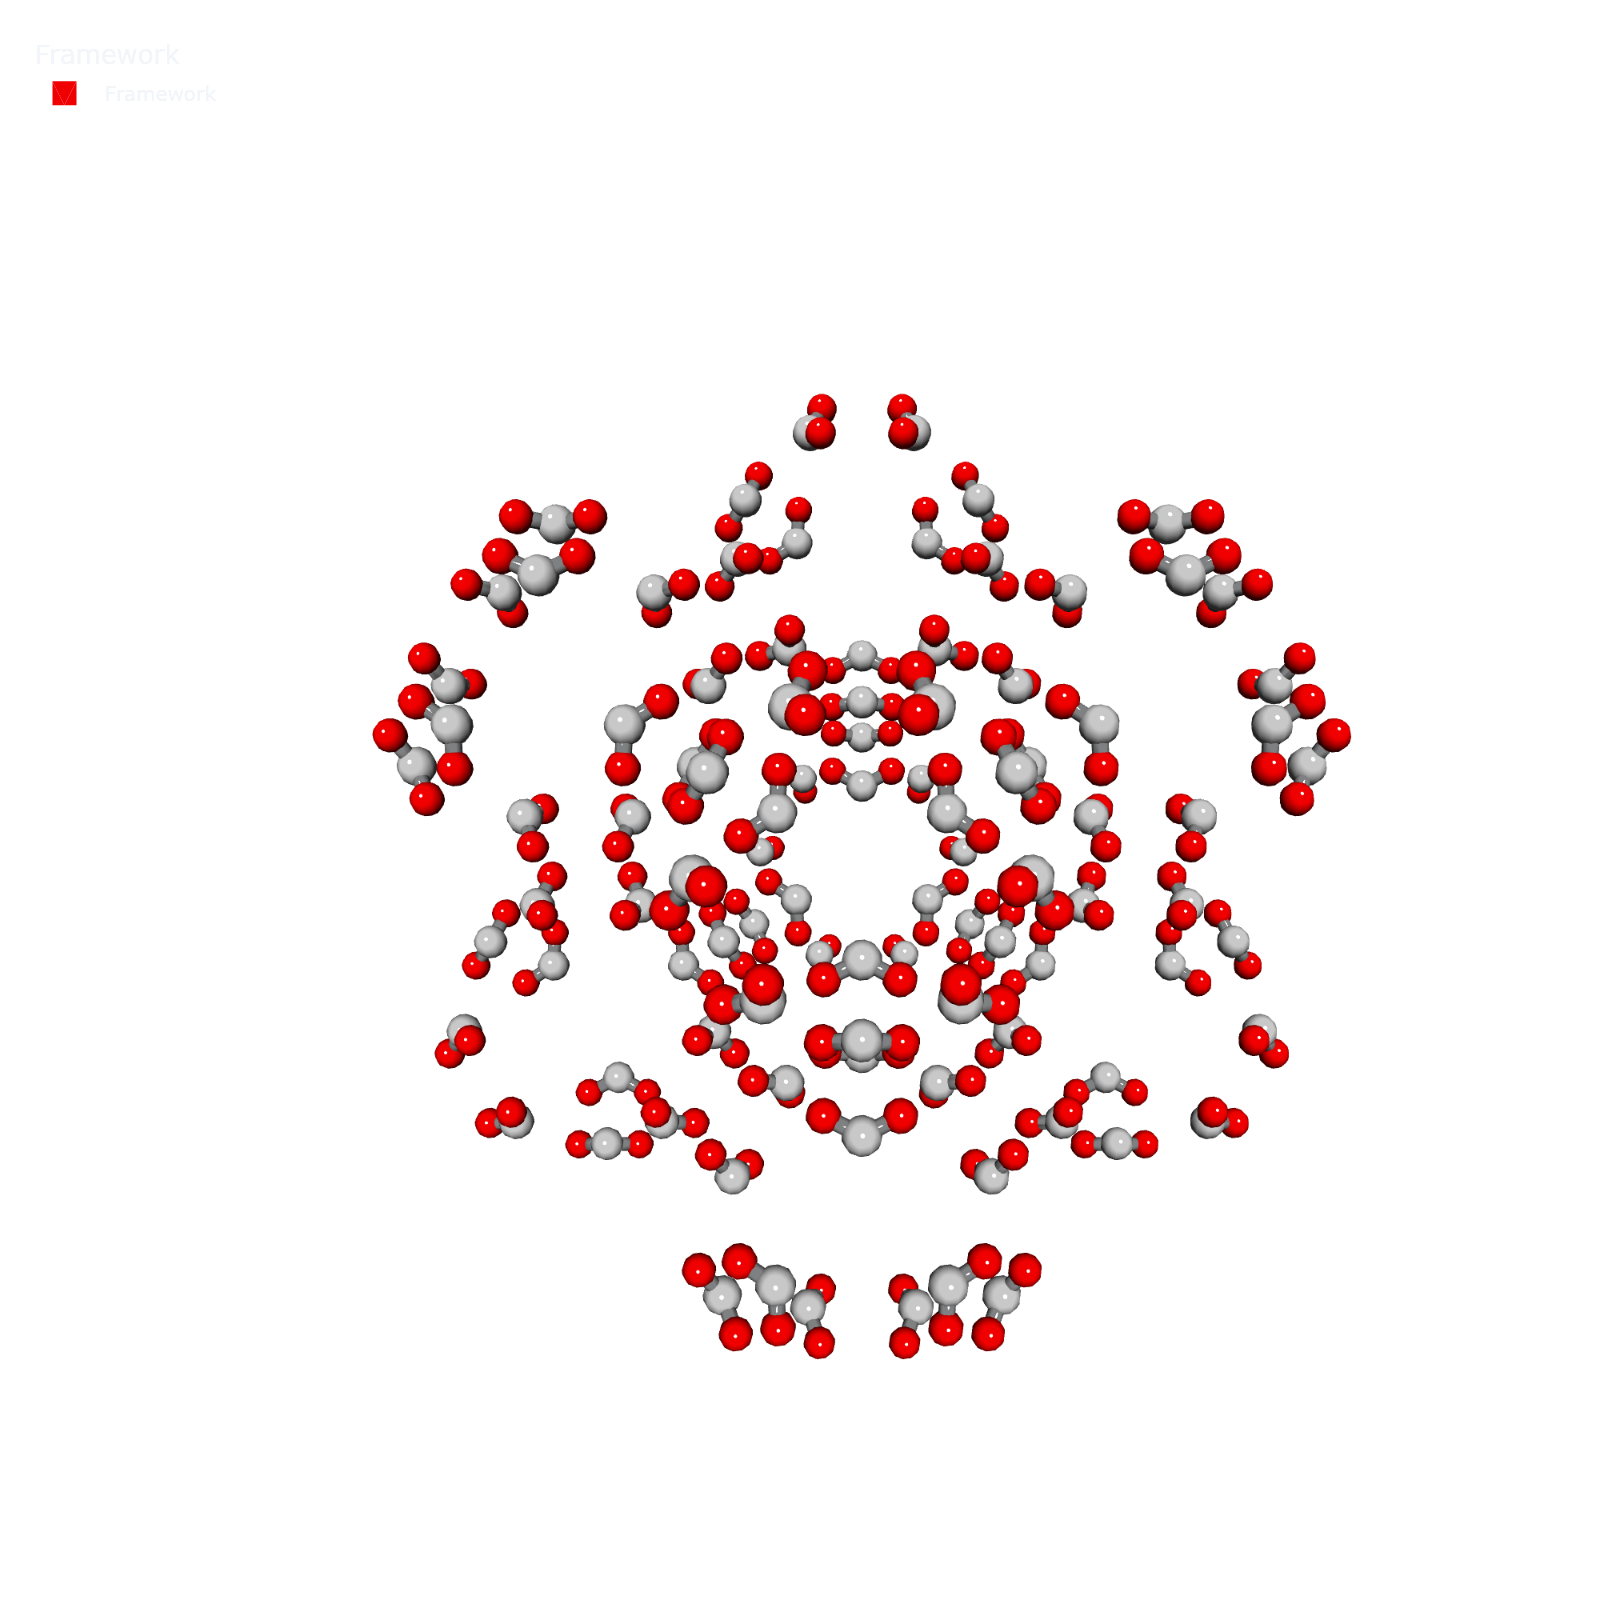

In [11]:
go.Figure(data=[*frame_subset_trace], layout=mgr.epic_layout).show(renderer='png', width=800, height=800, scale=2)    

##  Bonus: Visualize the whole material if you're curious
If you switch the renderer to 'notebook_connected' you can interact with the 3D visualization.
Please note that the code below also shows the periodic images of atoms that are necessary to visualize the bonds across periodic boundaries. This is purely for clarity. Basically, the number of atoms in the mat_updated will be greater than that in the original mat_atoms, because of these extra atoms.

c:\Users\Public\anaconda3\envs\test\lib\site-packages\ase\atoms.py:967: VisibleDeprecationWarning:

Use get_global_number_of_atoms() instead



No node props provided, using default set: [position, scaled_position, element and atomic_number]
No edge properties provided. Use the default set: [bond_order, bond_type]
isomorphic aromatic cycles is None, trying to calculate


c:\Users\Arun Gopalan\OneDrive - The University of Manchester\my_cloned_repos\mofography_general\mofography\mofography\analyze.py:524: VisibleDeprecationWarning:

Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.

c:\Users\Arun Gopalan\OneDrive - The University of Manchester\my_cloned_repos\mofography_general\mofography\mofography\visualize.py:768: UserWarning:

Optimal rotation is not uniquely or poorly defined for the given sets of vectors.



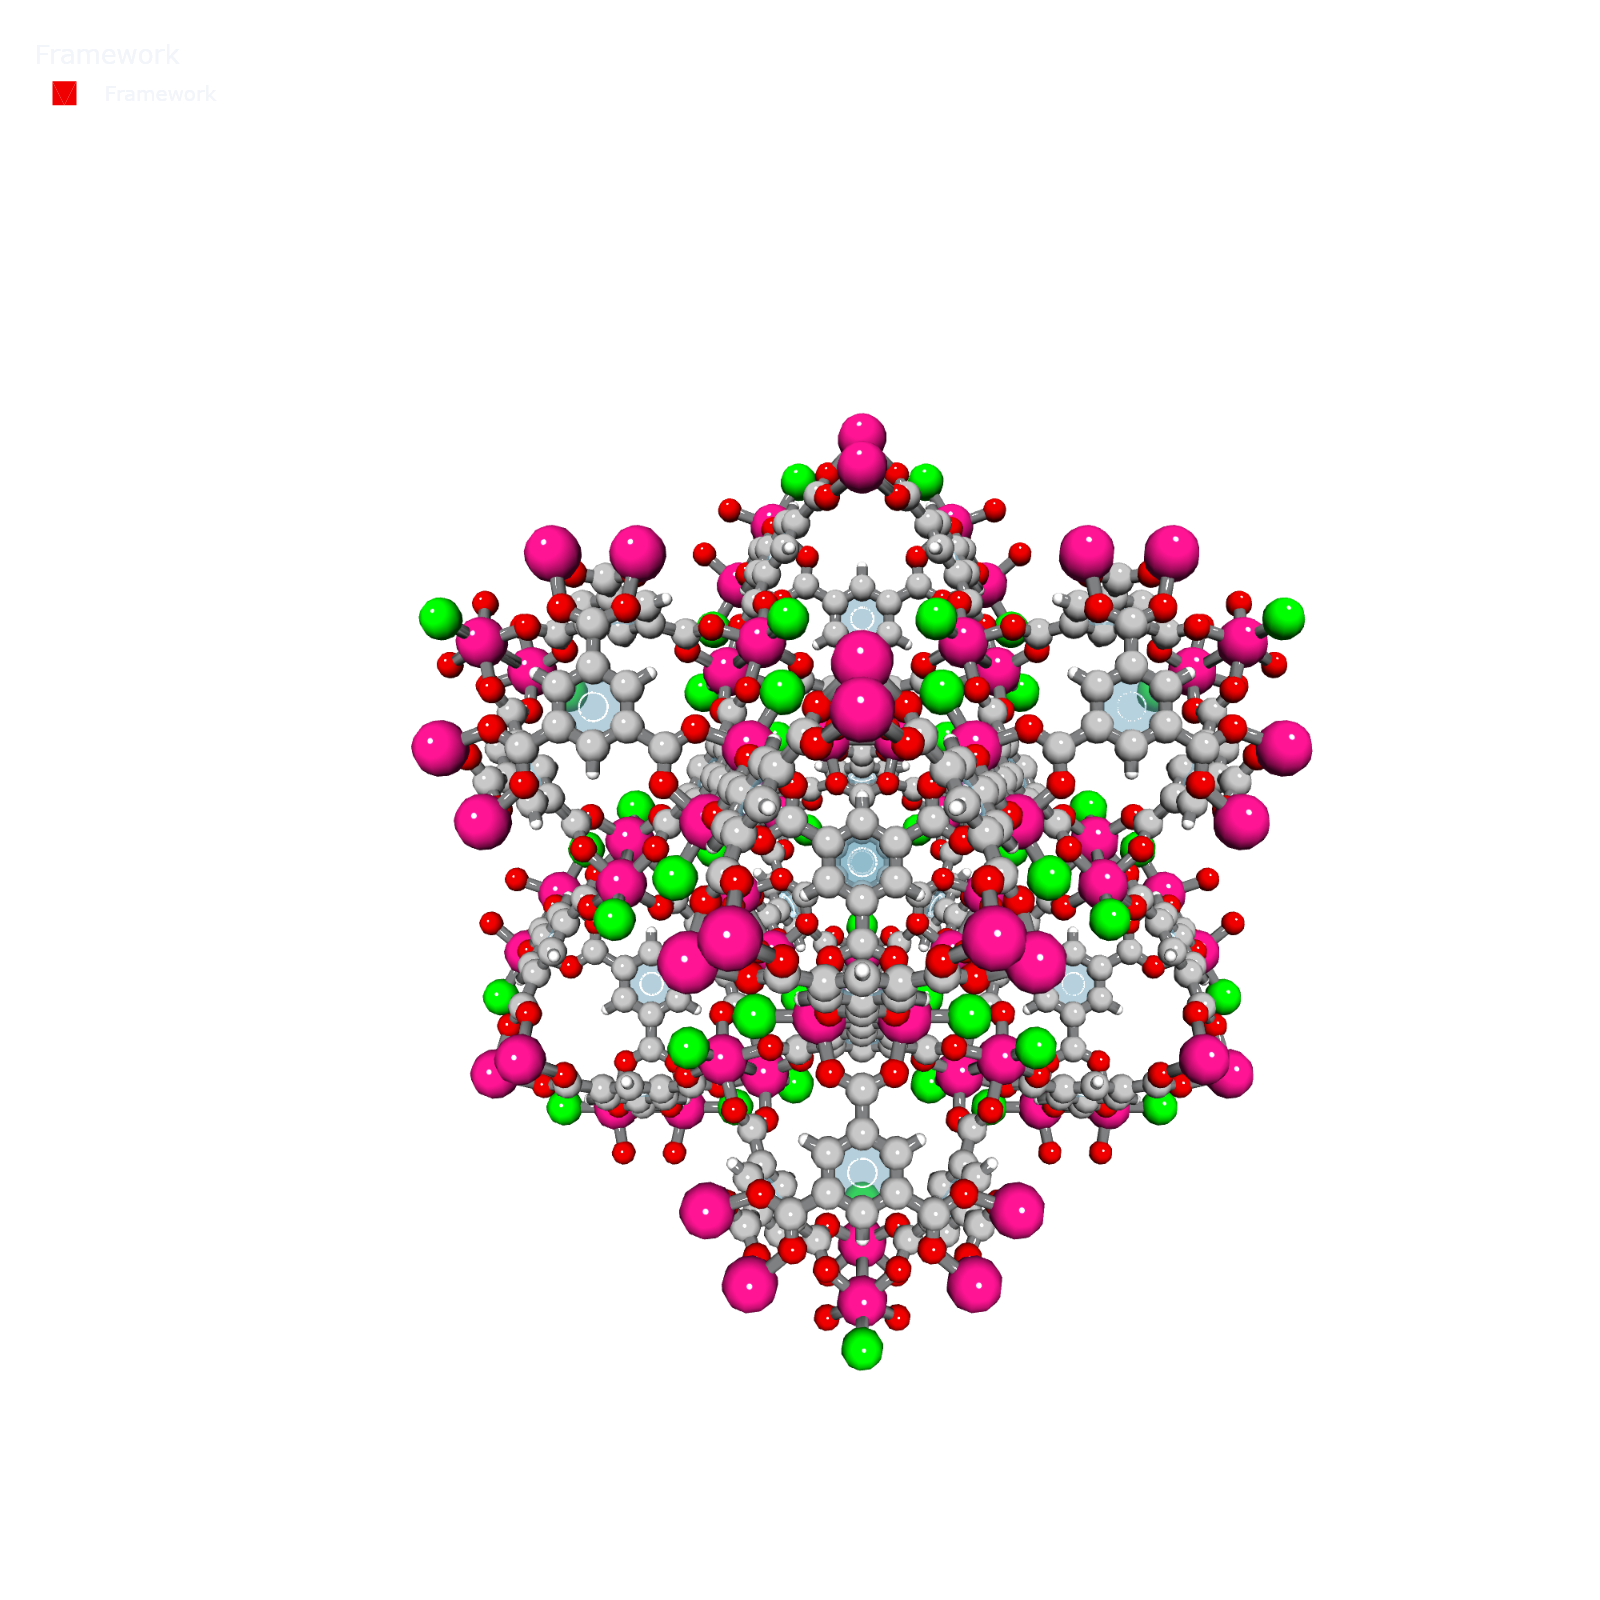

In [12]:
mat_updated = mgr.update_with_covalent_bonds(mat_atoms) 

frame_trace = mgr.plot_framework_as_mesh(mat_updated,stylize=True)

fig  = go.Figure(data=frame_trace)
fig.update(layout=mgr.epic_layout)
fig.show(renderer='png', width=800, height=800, scale=2)
# fig.show()

In [13]:
# def find_functional_groups(ase_atoms, functional_groups):
#     from rdkit import Chem
#     from networkx.algorithms import isomorphism
#     import mofography as mgr 

#     # Convert the supercell to a NetworkX graph
#     ase_atoms_updated = mgr.update_with_covalent_bonds(ase_atoms)
#     G = mgr.sgraph_from_atoms(ase_atoms_updated)

#     # Convert functional groups to NetworkX graphs
#     functional_group_graphs = {name: Chem.MolFromSmarts(smarts) for name, smarts in functional_groups.items()}

#     # Custom node match function
#     def node_match(node1, node2):
#         return node1['atomic_number'] == node2['atomic_number']

#     # Custom edge match function
#     def edge_match(edge1, edge2):
#         bond_type1 = edge1['bond_type'].lower()
#         bond_type2 = edge2['bond_type']
#         if bond_type1 == 'aromatic':
#             bond_type1 = 'double'
#         return bond_type1 == bond_type2

#     # Initialize matches with None for all functional groups
#     matches = {name: None for name in functional_groups.keys()}

#     # Search for functional groups in the molecule graph
#     for name, fg_mol in functional_group_graphs.items():
#         fg_G = nx.Graph()
#         for atom in fg_mol.GetAtoms():
#             fg_G.add_node(atom.GetIdx(),
#                           atomic_number=atom.GetAtomicNum(),
#                           formal_charge=atom.GetFormalCharge(),
#                           chirality=atom.GetChiralTag())
#         for bond in fg_mol.GetBonds():
#             bond_type = bond.GetBondType().name.lower()
#             if bond_type == 'aromatic':
#                 bond_type = 'double'
#             fg_G.add_edge(bond.GetBeginAtomIdx(),
#                           bond.GetEndAtomIdx(),
#                           bond_type=bond_type)
#         GM = isomorphism.GraphMatcher(G, fg_G, node_match=node_match, edge_match=edge_match)
#         if GM.subgraph_is_isomorphic():
#             matches[name] = list(GM.subgraph_isomorphisms_iter())

#     return matches

# def find_functional_groups2(ase_atoms, functional_groups):
#     from ase.io import write
#     from rdkit import Chem
#     from rdkit.Chem import AllChem
#     import networkx as nx
#     from networkx.algorithms import isomorphism
#     from io import StringIO

#     # Convert the supercell to an RDKit molecule
#     mol_str = StringIO()
#     write(mol_str, ase_atoms, format='mol')
#     mol = AllChem.MolFromMolBlock(mol_str.getvalue(), removeHs=False)
#     mol.UpdatePropertyCache(strict=False)
#     Chem.GetSymmSSSR(mol)

#     # Convert the RDKit molecule to a NetworkX graph
#     G = nx.Graph()
#     for atom in mol.GetAtoms():
#         G.add_node(atom.GetIdx(),
#                    atomic_num=atom.GetAtomicNum(),
#                    formal_charge=atom.GetFormalCharge(),
#                    chirality=atom.GetChiralTag())
#     for bond in mol.GetBonds():
#         G.add_edge(bond.GetBeginAtomIdx(),
#                    bond.GetEndAtomIdx(),
#                    bond_type=bond.GetBondType())

#     # Convert functional groups to NetworkX graphs
#     functional_group_graphs = {name: Chem.MolFromSmarts(smarts) for name, smarts in functional_groups.items()}

#     # Custom node match function
#     def node_match(node1, node2):
#         return node1['atomic_num'] == node2['atomic_num']

#     # Custom edge match function
#     def edge_match(edge1, edge2):
#         return edge1['bond_type'] == edge2['bond_type']

#     # Search for functional groups in the molecule graph
#     matches = {}
#     for name, fg_mol in functional_group_graphs.items():
#         fg_G = nx.Graph()
#         for atom in fg_mol.GetAtoms():
#             fg_G.add_node(atom.GetIdx(),
#                           atomic_num=atom.GetAtomicNum(),
#                           formal_charge=atom.GetFormalCharge(),
#                           chirality=atom.GetChiralTag())
#         for bond in fg_mol.GetBonds():
#             fg_G.add_edge(bond.GetBeginAtomIdx(),
#                           bond.GetEndAtomIdx(),
#                           bond_type=bond.GetBondType())
#         GM = isomorphism.GraphMatcher(G, fg_G, node_match=node_match, edge_match=edge_match)
#         if GM.subgraph_is_isomorphic():
#             matches[name] = list(GM.subgraph_isomorphisms_iter())

#     return matches

## Apply to CoRE MOFs in High Throughput

Now let's try to apply the functional group detection to the whole list of coremof atoms objects we compiled in the beginning of the notebook. We will look for a few common single-ring aromatic groups in the materials in the list. And to speed things up, and to make sure that our workflow won't fail even if one or more of the calculations fail, we'll use the 'futures' API from Dask. You can expect another detailed tutorial on using Dask for high throughput materials workflows coming soon. 

For me, It took about 30 minutes for about 7500 coremof materials on a core i7 laptop. Your mileage will vary depending on your hardware and the number of materials you're screening.


(PS: Notice that, if you have multiple functional groups, you can screen for them all at the same time, not one by one.😂)

In [14]:
# functional_groups = {
#     'carboxylate': '[C;X3](-[O;X1])-[O;X1]',
#     # Add more functional groups here
# }
aromatic_molecules = {
    "Benzene": "c1ccccc1",
    "Pyridine": "n1ccccc1",
    "Pyrrole": "c1cc[nH]c1",
    "Furane": "c1ccoc1",
    "Thiophene": "c1ccsc1",
    "Imidazole": "c1nccn1",
    "Pyrazole": "c1nncn1",
    "Oxazole": "c1nco1",
    "Thiazole": "c1ncs1",
    "Isoxazole": "c1noc1",
    "Isothiazole": "c1nsc1"
}
from dask import delayed
from dask.distributed import Client
matches_list = []
for atoms in tqdm(core_atoms):
        matches_list.append(delayed(mgr.find_functional_groups)(atoms,aromatic_molecules))



100%|██████████| 7509/7509 [00:01<00:00, 4564.61it/s]


Start a local dask cluster with 10 processes. If you do this on your laptop, the memory available to each worker will be your laptop's total memory divided by the number of workers. So, you might want to reduce the number of workers. 

In [15]:
import dask 
from dask.distributed import Client, progress
client = Client(n_workers=4)

let's take a look at the client object, it should contain a cluster with 10 workers. You can also go the dashboard link to see the status of the calculation. 

In [16]:
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 4
Total threads: 16,Total memory: 15.73 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:65400,Workers: 4
Dashboard: http://127.0.0.1:8787/status,Total threads: 16
Started: Just now,Total memory: 15.73 GiB
Comm: tcp://127.0.0.1:65429,Total threads: 4
Dashboard: http://127.0.0.1:65430/status,Memory: 3.93 GiB
Nanny: tcp://127.0.0.1:65403,


start running the jobs in the background. 

In [17]:
futures = dask.persist(*matches_list)

c:\Users\Public\anaconda3\envs\test\lib\site-packages\distributed\client.py:3163: UserWarning:

Sending large graph of size 177.85 MiB.
This may cause some slowdown.
Consider scattering data ahead of time and using futures.



If you are getting impatient, you can call compute in the foreground to collect whatever results are ready. Dask has many options for handling stuff like this, please refer the Dask documentation for such details. Ideally, I would look at the dashboard and wait for a little while before calling compute.

In [18]:
results = client.compute(futures)

Grab all the finished calculations and set the errored ones to None. Each entry in this list is a dictionary of dictionaries. The first dictionary contains all the functional group keys that we are looking for and the cooresponding entry is a nested dictionary that tells the atoms (groups of atom indices) that were flagged for that functional group. Just run it and look at one of the entries to understand better

In [19]:
outputs = [f.result() if f.status=='finished' else None for f in tqdm(results)]

  2%|▏         | 175/7509 [00:18<11:30, 10.62it/s]

KeyboardInterrupt: 

  2%|▏         | 175/7509 [00:29<11:30, 10.62it/s]

In [20]:
results

[<Future: pending, key: find_functional_groups-9fd10f69-6d4d-4381-af5f-275cb4aa9e6b>,
 <Future: finished, type: dict, key: find_functional_groups-3e68af8d-bb8e-47c2-8aac-2b768b8b4f7d>,
 <Future: finished, type: dict, key: find_functional_groups-62f9ad26-edee-4511-ab2d-cee55e22528c>,
 <Future: finished, type: dict, key: find_functional_groups-6617cc58-546c-4375-8658-9985d9cbb141>,
 <Future: pending, key: find_functional_groups-cff85e7a-12e3-4e0d-8439-6aea05e094a1>,
 <Future: finished, type: dict, key: find_functional_groups-11b003f9-a80b-4c54-88a4-f6c0e4d6f685>,
 <Future: finished, type: dict, key: find_functional_groups-15ef6b69-527e-4b1d-804d-59e7756ee316>,
 <Future: pending, key: find_functional_groups-83f892d9-d675-4fb6-98d9-95505c6f9fbd>,
 <Future: finished, type: dict, key: find_functional_groups-6ac0e3cb-d77e-4dd5-8196-722bad8f2d27>,
 <Future: finished, type: dict, key: find_functional_groups-03930210-deb6-4d13-b6a0-2372d4368e28>,
 <Future: pending, key: find_functional_groups-ca

In [ ]:
outputs[5]

(optional) save the matches to a pickle file if you need to for plotting or further analysis.

In [ ]:
pickle.dump(outputs,open('functional_groups_core_gt_05.pkl','wb'))

Let's count the number of materials that contain each of the functional groups so that we can plot it later.

In [ ]:
def count_not_none_entries(list_of_dicts):
    counts = {key: 0 for key in list_of_dicts[0].keys()}
    for dict_ in list_of_dicts:
        for key, value in dict_.items():
            if value is not None:
                counts[key] += 1
    return counts

# Example usage:


print(count_not_none_entries(outputs))

Visualize the materials counts for each functional group as a bar plot using Plotly (if you switch out the renderer to 'notebook_connected' you can interact with the plot).

In [ ]:
import plotly.graph_objects as go

def plot_counts(counts):
    fig = go.Figure(data=[
        go.Bar(name='Counts', x=list(counts.keys()), y=list(counts.values()))
    ])
    fig.update_layout(title='Counts of single ring aromatics in CoRE MOF 2019 with vf > 0.5',
                      xaxis_title='single ring aromatics',
                      yaxis_title='Counts')
    fig.write_image('single_ring_aromatics_countes.png', width=800, height=400, scale=2)
    fig.show(renderer='png')

# Example usage:
counts = count_not_none_entries(outputs)
plot_counts(counts)

Pretty cool, right? From here I'll leave it to you to do what ever post processing you want. 